# Phase 4 Checks: Track A Toy MCMC

Verifies `src/models/stochastic/toy_mcmc.py` and `src/models/stochastic/am_sampler.py`.
Re-run after any change to either file.

**Sections**
1. Setup
2. `league_baseline`: league level and home ice
3. `pair_games`: one pair's head-to-head games
4. `make_log_posterior`: matches the Poisson formula
5. `simulate_pair_games`: fake games have the right rates
6. Test 1: one fit on 15 simulated games (traces, ACF, R-hat)
7. Test 2: 500 games narrows the posterior
8. Test 3: coverage over 100 seeds *(the most important check: is the uncertainty honest?)*
9. Test 4: MCMC matches the exact posterior
10. Real pair

Each check prints **PASS** or **CHECK**. A CHECK isn't always a bug; read the note next to it.

**The exact posterior used in sections 4 and 9.** With a flat prior on $d$, the posterior of
$r = e^{d}$ is $\text{Gamma}(Y, B)$, where $Y$ = total goals and $B = \sum_g e^{\alpha_0 + \eta \cdot \text{home}_g}$.
So $E[d] = \psi(Y) - \log B$ and $\text{sd}(d) = \sqrt{\psi_1(Y)}$ (digamma and trigamma),
ignoring the $[-1, 1]$ bounds, which are far from where the posterior sits.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special

from src.data.db import get_connection
from src.processing.team_strength import team_game_xg
from src.models.stochastic.toy_mcmc import (
    PARAM_NAMES, PRIOR_LO, PRIOR_HI,
    league_baseline, pair_games, make_log_posterior, simulate_pair_games,
)
from src.models.stochastic.am_sampler import adaptive_metropolis, autocorrelation, plot_traces, plot_acf

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

def exact_posterior(games, alpha0, eta):
    """Exact posterior mean and sd of (d_A, d_B) under a flat prior."""
    out = {}
    for name, goals, home in [("d_A", games.goals_a, games.a_home),
                              ("d_B", games.goals_b, 1 - games.a_home)]:
        Y = goals.sum()
        B = np.exp(alpha0 + eta * home).sum()
        out[name] = (special.digamma(Y) - np.log(B), np.sqrt(special.polygamma(1, Y)))
    return out

def interval(samples, level=0.90):
    lo, hi = (1 - level) / 2, 1 - (1 - level) / 2
    return np.quantile(samples, [lo, hi], axis=0)    # shape (2, d)

def rhat(chains):
    """Gelman-Rubin R-hat. chains: (m, n) for one parameter."""
    m, n = chains.shape
    W = chains.var(axis=1, ddof=1).mean()
    B = n * chains.mean(axis=1).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

# Pair used in section 3 and section 10 (abbreviations exactly as in tg["team"])
TEAM_A, TEAM_B = "COL", "DAL"

# True values for the simulated tests
TRUE = np.array([0.15, -0.10])

conn = get_connection()
tg = team_game_xg(conn)
print(f"team-games: {len(tg):,}")

team-games: 13,120


## 2. `league_baseline`: league level and home ice

In [2]:
alpha0, eta = league_baseline(tg)
print(f"alpha0 = {alpha0:.4f}  ({np.exp(alpha0):.3f} away goals/game)")
print(f"eta    = {eta:.4f}  (home scores {np.exp(eta) - 1:.1%} more)")

home_rate = tg.loc[tg.is_home == 1, "gf_xg"].mean()
away_rate = tg.loc[tg.is_home == 0, "gf_xg"].mean()
check("alpha0 matches log(away rate)", np.isclose(alpha0, np.log(away_rate)))
check("eta matches log(home / away)", np.isclose(eta, np.log(home_rate / away_rate)))
check("returns plain floats", isinstance(alpha0, float) and isinstance(eta, float))
check("alpha0 near log 3 (2.5-3.5 goals)", 2.5 < np.exp(alpha0) < 3.5)
check("home ice positive and modest (0 < eta < 0.15)", 0 < eta < 0.15)

alpha0 = 1.0291  (2.799 away goals/game)
eta    = 0.0715  (home scores 7.4% more)
PASS   alpha0 matches log(away rate)
PASS   eta matches log(home / away)
PASS   returns plain floats
PASS   alpha0 near log 3 (2.5-3.5 goals)
PASS   home ice positive and modest (0 < eta < 0.15)


## 3. `pair_games`: one pair's head-to-head games

In [3]:
if TEAM_A not in set(tg.team) or TEAM_B not in set(tg.team):
    print("Pick teams from:", sorted(tg.team.unique()))

games = pair_games(tg, TEAM_A, TEAM_B)
print(f"{TEAM_A} vs {TEAM_B}: {len(games)} games, {TEAM_A} home in {games.a_home.sum()}")
display(games.head())

check("columns match the contract",
      list(games.columns) == ["game_id", "game_date", "season", "a_home", "goals_a", "goals_b"])
check("one row per game (no double count)", games.game_id.is_unique)
check("a_home is 0/1", set(games.a_home.unique()) <= {0, 1})
check("sorted by date", games.game_date.is_monotonic_increasing)
check("home split roughly even (30-70%)", 0.3 <= games.a_home.mean() <= 0.7,
      f"{games.a_home.mean():.0%}")

# The other team's rows must hold the same games with goals swapped
flip = pair_games(tg, TEAM_B, TEAM_A).set_index("game_id").loc[games.game_id]
check("same games seen from the other side", len(flip) == len(games))
check("goals swap correctly",
      (flip.goals_a.values == games.goals_b.values).all() and
      (flip.goals_b.values == games.goals_a.values).all())
check("home flag flips", (flip.a_home.values == 1 - games.a_home.values).all())

COL vs DAL: 18 games, COL home in 9


,game_id,game_date,season,a_home,goals_a,goals_b
0,2021020313,2021-11-26,20212022,0,1,3
1,2021020563,2022-02-13,20212022,0,3,0
2,2021020549,2022-02-15,20212022,1,1,3
3,2022020298,2022-11-21,20222023,0,2,2
4,2022020339,2022-11-26,20222023,1,4,1


PASS   columns match the contract
PASS   one row per game (no double count)
PASS   a_home is 0/1
PASS   sorted by date
PASS   home split roughly even (30-70%)   (50%)
PASS   same games seen from the other side
PASS   goals swap correctly
PASS   home flag flips


## 4. `make_log_posterior`: matches the Poisson formula

Differences in `log_post` must equal differences in the full Poisson log-likelihood
(scipy, including the `log(y!)` term that `log_post` drops). The peak must sit at the
exact answer.

In [4]:
log_post = make_log_posterior(games, alpha0, eta)

def scipy_loglik(x):
    lam_a = np.exp(alpha0 + eta * games.a_home + x[0])
    lam_b = np.exp(alpha0 + eta * (1 - games.a_home) + x[1])
    return stats.poisson.logpmf(games.goals_a, lam_a).sum() + stats.poisson.logpmf(games.goals_b, lam_b).sum()

x1, x2 = np.array([0.0, 0.0]), np.array([0.3, -0.2])
diff_ours = log_post(x2) - log_post(x1)
diff_scipy = scipy_loglik(x2) - scipy_loglik(x1)
check("finite inside the prior", np.isfinite(log_post(x1)))
check("-inf outside the prior", log_post(np.array([PRIOR_HI + 0.5, 0.0])) == -np.inf
                                 and log_post(np.array([0.0, PRIOR_LO - 0.5])) == -np.inf)
check("differences match scipy Poisson", np.isclose(diff_ours, diff_scipy),
      f"{diff_ours:.6f} vs {diff_scipy:.6f}")

# Peak of the likelihood (the MLE) in closed form
d_hat = np.array([
    np.log(games.goals_a.sum() / np.exp(alpha0 + eta * games.a_home).sum()),
    np.log(games.goals_b.sum() / np.exp(alpha0 + eta * (1 - games.a_home)).sum()),
])
print("MLE (d_A, d_B):", d_hat.round(4))
higher = all(log_post(d_hat) > log_post(d_hat + step)
             for step in [np.array([0.05, 0]), np.array([-0.05, 0]), np.array([0, 0.05]), np.array([0, -0.05])])
check("log_post peaks at the MLE", higher)

PASS   finite inside the prior
PASS   -inf outside the prior
PASS   differences match scipy Poisson   (-1.107314 vs -1.107314)
MLE (d_A, d_B): [ 0.1217 -0.0438]
PASS   log_post peaks at the MLE


## 5. `simulate_pair_games`: fake games have the right rates

In [5]:
fake = simulate_pair_games(20000, TRUE[0], TRUE[1], alpha0, eta, seed=1)
display(fake.head())

true_a = np.exp(alpha0 + eta * fake.a_home + TRUE[0]).mean()
true_b = np.exp(alpha0 + eta * (1 - fake.a_home) + TRUE[1]).mean()
check("same columns as pair_games", list(fake.columns) == list(games.columns))
check("A home in exactly half", fake.a_home.mean() == 0.5)
check("A goals match the true rate (within 1%)", abs(fake.goals_a.mean() / true_a - 1) < 0.01,
      f"{fake.goals_a.mean():.3f} vs {true_a:.3f}")
check("B goals match the true rate (within 1%)", abs(fake.goals_b.mean() / true_b - 1) < 0.01,
      f"{fake.goals_b.mean():.3f} vs {true_b:.3f}")
check("same seed gives same games",
      simulate_pair_games(15, *TRUE, alpha0, eta, seed=7).equals(simulate_pair_games(15, *TRUE, alpha0, eta, seed=7)))

,game_id,game_date,season,a_home,goals_a,goals_b
0,0,2000-01-01,0,1,4,1
1,1,2000-01-08,0,0,4,3
2,2,2000-01-15,0,1,5,2
3,3,2000-01-22,0,0,2,2
4,4,2000-01-29,0,1,3,1


PASS   same columns as pair_games
PASS   A home in exactly half
PASS   A goals match the true rate (within 1%)   (3.372 vs 3.372)
PASS   B goals match the true rate (within 1%)   (2.634 vs 2.626)
PASS   same seed gives same games


## 6. Test 1: one fit on 15 simulated games

Four chains from different seeds and starting points, so R-hat can be computed.
R-hat compares the spread between chains to the spread within them; below 1.01 means they agree.

In [6]:
sim15 = simulate_pair_games(15, *TRUE, alpha0, eta, seed=42)
lp15 = make_log_posterior(sim15, alpha0, eta)

starts = [np.array([0.0, 0.0]), np.array([0.5, 0.5]), np.array([-0.5, -0.5]), np.array([0.5, -0.5])]
chains, infos = [], []
for i, x0 in enumerate(starts):
    s, info = adaptive_metropolis(lp15, d=2, n_burn=5000, n_main=50000, seed=100 + i, x0=x0, verbose=False)
    chains.append(s); infos.append(info)
chains = np.array(chains)                 # (4, 50000, 2)
samples = chains[0]

lo, hi = interval(samples)
for j, name in enumerate(PARAM_NAMES):
    print(f"{name}: truth {TRUE[j]:+.3f}   mean {samples[:, j].mean():+.3f}   "
          f"90% [{lo[j]:+.3f}, {hi[j]:+.3f}]   sd {samples[:, j].std():.3f}")

acc = [info["main_acc_rate"] for info in infos]
print("main acceptance per chain:", np.round(acc, 3))
check("acceptance in 0.2-0.5", all(0.2 <= a <= 0.5 for a in acc))
check("truth inside 90% interval (both)", all(lo[j] <= TRUE[j] <= hi[j] for j in range(2)),
      "fails ~19% of the time by chance with two parameters; section 8 is the real test")
r = [rhat(chains[:, :, j]) for j in range(2)]
check("R-hat < 1.01 (both)", max(r) < 1.01, f"{np.round(r, 4)}")
acf = [autocorrelation(samples[:, j], max_lag=200) for j in range(2)]
lag_drop = [int(np.argmax(a < 0.05)) for a in acf]
check("ACF drops below 0.05 within 50 lags", max(lag_drop) <= 50, f"lags {lag_drop}")

d_A: truth +0.150   mean +0.183   90% [-0.045, +0.404]   sd 0.137
d_B: truth -0.100   mean -0.258   90% [-0.552, +0.019]   sd 0.173
main acceptance per chain: [0.37  0.361 0.352 0.359]
PASS   acceptance in 0.2-0.5
PASS   truth inside 90% interval (both)   (fails ~19% of the time by chance with two parameters; section 8 is the real test)
PASS   R-hat < 1.01 (both)   ([1.0001 1.0001])
PASS   ACF drops below 0.05 within 50 lags   (lags [11, 11])


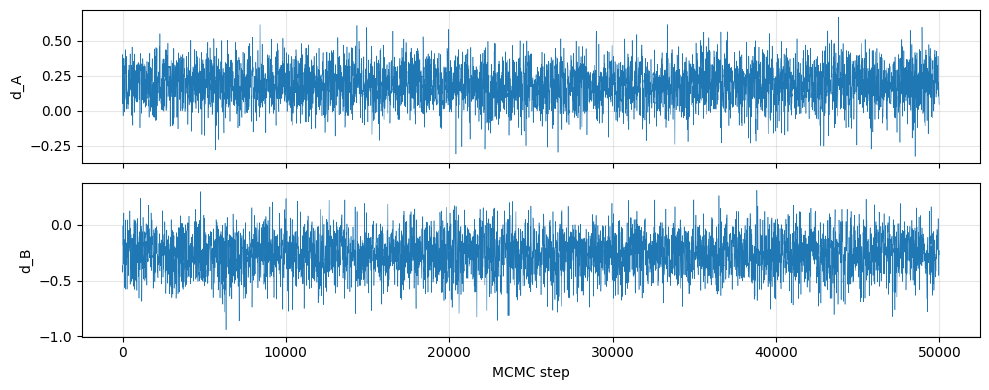

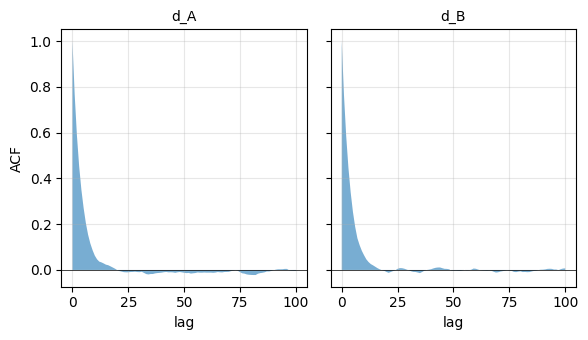

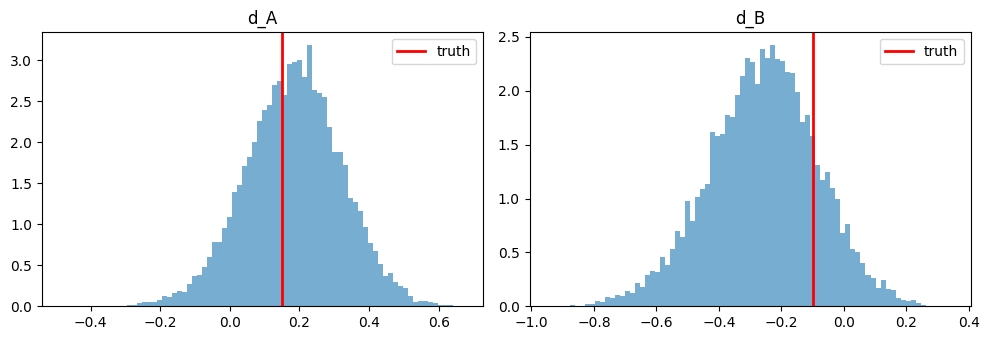

In [7]:
plot_traces(samples, PARAM_NAMES, thin=10);
plot_acf(samples, PARAM_NAMES, max_lag=100);

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, ax in enumerate(axes):
    ax.hist(samples[:, j], bins=80, density=True, alpha=0.6)
    ax.axvline(TRUE[j], color="red", lw=2, label="truth")
    ax.set_title(PARAM_NAMES[j]); ax.legend()
plt.tight_layout()

## 7. Test 2: 500 games narrows the posterior

Posterior sd shrinks like $1/\sqrt{n}$, so 500 vs 15 games should narrow it about $\sqrt{500/15} \approx 5.8\times$.

In [8]:
sim500 = simulate_pair_games(500, *TRUE, alpha0, eta, seed=43)
s500, info500 = adaptive_metropolis(make_log_posterior(sim500, alpha0, eta), d=2,
                                    n_burn=5000, n_main=50000, seed=200, verbose=False)
lo5, hi5 = interval(s500)
ratio = samples.std(axis=0) / s500.std(axis=0)
for j, name in enumerate(PARAM_NAMES):
    print(f"{name}: truth {TRUE[j]:+.3f}   mean {s500[:, j].mean():+.3f}   "
          f"90% [{lo5[j]:+.3f}, {hi5[j]:+.3f}]   narrower by {ratio[j]:.1f}x")
check("truth inside 90% interval (both)", all(lo5[j] <= TRUE[j] <= hi5[j] for j in range(2)))
check("narrows 4-8x (expect ~5.8)", all(4 <= r <= 8 for r in ratio), f"{ratio.round(1)}")

d_A: truth +0.150   mean +0.175   90% [+0.135, +0.215]   narrower by 5.7x
d_B: truth -0.100   mean -0.125   90% [-0.172, -0.079]   narrower by 6.1x
PASS   truth inside 90% interval (both)
PASS   narrows 4-8x (expect ~5.8)   ([5.7 6.1])


## 8. Test 3: coverage over 100 seeds

100 independent 15-game datasets, each fit with a shorter chain. A 90% interval should contain
the truth about 90 times; 84-96 is within normal luck (binomial, about ±2 sd). Takes about a minute.

In [9]:
N_REPS = 100
hits = np.zeros((N_REPS, 2), dtype=bool)
for rep in range(N_REPS):
    sim = simulate_pair_games(15, *TRUE, alpha0, eta, seed=1000 + rep)
    s, _ = adaptive_metropolis(make_log_posterior(sim, alpha0, eta), d=2,
                               n_burn=2000, n_main=10000, seed=5000 + rep, verbose=False)
    lo_r, hi_r = interval(s)
    hits[rep] = (lo_r <= TRUE) & (TRUE <= hi_r)

cover = hits.sum(axis=0)
for j, name in enumerate(PARAM_NAMES):
    print(f"{name}: truth inside 90% interval in {cover[j]}/{N_REPS}")
    check(f"{name} coverage 84-96", 84 <= cover[j] <= 96)

d_A: truth inside 90% interval in 90/100
PASS   d_A coverage 84-96
d_B: truth inside 90% interval in 96/100
PASS   d_B coverage 84-96


## 9. Test 4: MCMC matches the exact posterior

Uses the Gamma result from the top of the notebook. Monte Carlo error on the mean is about
sd / √(effective samples), so agreement to ~0.01 is expected with 50,000 draws.

In [10]:
exact = exact_posterior(sim15, alpha0, eta)
for j, name in enumerate(PARAM_NAMES):
    m_ex, sd_ex = exact[name]
    m_mc, sd_mc = samples[:, j].mean(), samples[:, j].std()
    print(f"{name}: exact mean {m_ex:+.4f} sd {sd_ex:.4f}   MCMC mean {m_mc:+.4f} sd {sd_mc:.4f}")
    check(f"{name} mean within 0.01", abs(m_mc - m_ex) < 0.01)
    check(f"{name} sd within 5%", abs(sd_mc / sd_ex - 1) < 0.05)

d_A: exact mean +0.1849 sd 0.1380   MCMC mean +0.1831 sd 0.1370
PASS   d_A mean within 0.01
PASS   d_A sd within 5%
d_B: exact mean -0.2596 sd 0.1728   MCMC mean -0.2578 sd 0.1734
PASS   d_B mean within 0.01
PASS   d_B sd within 5%


## 10. Real pair

Same fit on the real head-to-head games from section 3. Expect wide intervals. A positive `d_A`
means TEAM_A scores more against TEAM_B than a league-average team would against a league-average defense.

COL vs DAL, 18 games, acceptance 0.346
d_A: mean +0.111   90% [-0.107, +0.320]   rate x1.12   exact mean +0.113
PASS   d_A matches exact (within 0.015)
d_B: mean -0.053   90% [-0.294, +0.168]   rate x0.95   exact mean -0.054
PASS   d_B matches exact (within 0.015)
PASS   acceptance in 0.2-0.5
PASS   interval well inside the prior box   (if not, widen PRIOR_LO / PRIOR_HI)


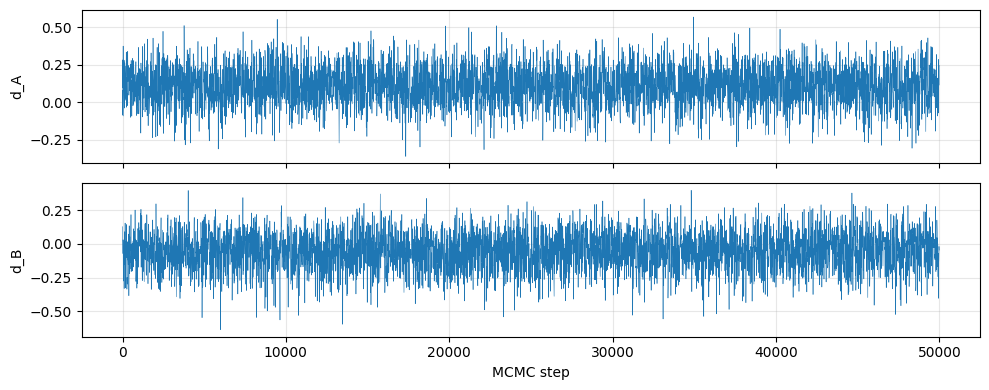

In [11]:
s_real, info_real = adaptive_metropolis(log_post, d=2, n_burn=5000, n_main=50000, seed=300, verbose=False)
lo_r, hi_r = interval(s_real)
exact_r = exact_posterior(games, alpha0, eta)
print(f"{TEAM_A} vs {TEAM_B}, {len(games)} games, acceptance {info_real['main_acc_rate']:.3f}")
for j, name in enumerate(PARAM_NAMES):
    m = s_real[:, j].mean()
    print(f"{name}: mean {m:+.3f}   90% [{lo_r[j]:+.3f}, {hi_r[j]:+.3f}]   "
          f"rate x{np.exp(m):.2f}   exact mean {exact_r[name][0]:+.3f}")
    check(f"{name} matches exact (within 0.015)", abs(m - exact_r[name][0]) < 0.015)
check("acceptance in 0.2-0.5", 0.2 <= info_real["main_acc_rate"] <= 0.5)
check("interval well inside the prior box", lo_r.min() > PRIOR_LO + 0.1 and hi_r.max() < PRIOR_HI - 0.1,
      "if not, widen PRIOR_LO / PRIOR_HI")

plot_traces(s_real, PARAM_NAMES, thin=10);